In [6]:
import numpy as np
import pandas as pd
from geopy.distance import geodesic

# ==========================================
# 1. LOAD DATASETS
# ==========================================
# Load station coordinates
df_stations = pd.read_csv("Stations.csv")
richmond_coords = df_stations[df_stations["station"].str.lower() == "richmond"][["latitude", "longitude"]].iloc[0]
st_lat, st_lon = richmond_coords["latitude"], richmond_coords["longitude"]

# Load cleaned air quality & hotspots
df_aq = pd.read_csv("Richmond_clean.csv")
df_aq.columns = df_aq.columns.str.strip()

# Fix the '24:00' / '24:00:00' hour format issue
time_series = df_aq["Time"].str.strip()
is_24_hr = time_series.str.startswith("24:")

# Replace '24:' with '00:'
cleaned_time = time_series.copy()
cleaned_time[is_24_hr] = cleaned_time[is_24_hr].str.replace("^24:", "00:", regex=True)

# Combine and parse to datetime
df_aq["datetime"] = pd.to_datetime(df_aq["Date"] + " " + cleaned_time, format="mixed")

# Add 1 day to the rows that originally had hour '24:'
df_aq.loc[is_24_hr, "datetime"] += pd.to_timedelta(1, unit="D")

# Map Wind_Direction to wind_direction to prevent KeyError if expected by downstream features
if "Wind_Direction" in df_aq.columns and "wind_direction" not in df_aq.columns:
    df_aq["wind_direction"] = df_aq["Wind_Direction"]

df_hotspots = pd.read_csv("Hotspots_clean.csv")

# Ensure datetime columns are proper datetime types
df_aq["datetime"] = pd.to_datetime(df_aq["datetime"])
df_hotspots["datetime"] = pd.to_datetime(df_hotspots["datetime"])

# Sort air quality chronologically
df_aq = df_aq.sort_values("datetime").reset_index(drop=True)

# Create a floor-to-hour datetime column in hotspots for hourly grouping
df_hotspots["hourly_dt"] = df_hotspots["datetime"].dt.floor("h")


# ==========================================
# 2. SPATIAL CALCULATIONS (HELPERS)
# ==========================================
def calculate_bearing(lat1, lon1, lat2, lon2):
    """Calculates directional bearing from point 1 to point 2."""
    lat1, lat2 = np.radians(lat1), np.radians(lat2)
    diff = np.radians(lon2 - lon1)
    x = np.sin(diff) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(
        lat2
    ) * np.cos(diff)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360


def compute_hourly_fire_features(group, st_lat, st_lon, wind_dir):
    """Computes fire distance, count, FRP totals, and upwind exposure for a 1-hour block."""
    if group.empty:
        return pd.Series({
            "nearest_fire_km": np.nan,
            "fires_50km": 0,
            "fires_100km": 0,
            "fires_200km": 0,
            "frp_50km": 0.0,
            "frp_100km": 0.0,
            "frp_200km": 0.0,
            "upwind_exposure": 0.0,
        })

    # Vectorized / looped distance calculations
    distances = []
    bearings = []
    powers = group["power"].values

    for _, row in group.iterrows():
        d = geodesic((st_lat, st_lon), (row["latitude"], row["longitude"])).km
        b = calculate_bearing(
            st_lat, st_lon, row["latitude"], row["longitude"]
        )
        distances.append(d)
        bearings.append(b)

    distances = np.array(distances)
    bearings = np.array(bearings)

    # Nearest fire
    nearest = distances.min()

    # Counts within radii
    f50 = np.sum(distances <= 50)
    f100 = np.sum(distances <= 100)
    f200 = np.sum(distances <= 200)

    # FRP sums
    frp50 = np.sum(powers[distances <= 50])
    frp100 = np.sum(powers[distances <= 100])
    frp200 = np.sum(powers[distances <= 200])

    # Upwind Exposure Index calculation
    if np.isnan(wind_dir):
        upwind = 0.0
    else:
        # Angle between wind direction and fire bearing
        angle_diff = np.abs(bearings - wind_dir)
        angle_diff = np.minimum(angle_diff, 360 - angle_diff)
        weights = np.maximum(0, np.cos(np.radians(angle_diff)))
        # Inverse distance squared weighting
        valid_mask = distances > 0
        upwind = np.sum(
            (powers[valid_mask] * weights[valid_mask])
            / (distances[valid_mask] ** 2)
        )

    return pd.Series({
        "nearest_fire_km": nearest,
        "fires_50km": f50,
        "fires_100km": f100,
        "fires_200km": f200,
        "frp_50km": frp50,
        "frp_100km": frp100,
        "frp_200km": frp200,
        "upwind_exposure": upwind,
    })


# ==========================================
# 3. MERGE FIRE FEATURES INTO AIR QUALITY
# ==========================================
fire_feature_rows = []

# Group hotspots by hourly timestamp for fast matching
hotspots_grouped = dict(list(df_hotspots.groupby("hourly_dt")))

for idx, row in df_aq.iterrows():
    dt = row["datetime"]
    wind_dir = row.get("wind_direction", np.nan)

    # Fetch hotspots matching current hour
    hourly_fires = hotspots_grouped.get(dt, pd.DataFrame())

    # Compute spatial features
    features = compute_hourly_fire_features(
        hourly_fires, st_lat, st_lon, wind_dir
    )
    fire_feature_rows.append(features)

df_fire_features = pd.DataFrame(fire_feature_rows)
df_master = pd.concat([df_aq, df_fire_features], axis=1)

# Fill NaN in nearest_fire_km with a max threshold (e.g., 999 km) if no fire present
df_master["nearest_fire_km"] = df_master["nearest_fire_km"].fillna(999.0)

# ==========================================
# 4. TEMPORAL & LAG FEATURE ENGINEERING
# ==========================================
# Lag Features (PM2.5 & FRP)
for lag in [1, 3, 6, 24]:
    df_master[f"pm25_lag{lag}"] = df_master["PM25"].shift(lag)
    df_master[f"frp_lag{lag}"] = df_master["frp_200km"].shift(lag)

# Calendar & Cyclical Features
df_master["hour"] = df_master["datetime"].dt.hour
df_master["month"] = df_master["datetime"].dt.month


def get_season(month):
    if month in [12, 1, 2]:
        return "Summer"
    if month in [3, 4, 5]:
        return "Autumn"
    if month in [6, 7, 8]:
        return "Winter"
    return "Spring"


df_master["season"] = df_master["month"].apply(get_season)

# Sine/Cosine transformations for cyclical time modeling
df_master["sin_hour"] = np.sin(2 * np.pi * df_master["hour"] / 24.0)
df_master["cos_hour"] = np.cos(2 * np.pi * df_master["hour"] / 24.0)
df_master["sin_month"] = np.sin(2 * np.pi * df_master["month"] / 12.0)
df_master["cos_month"] = np.cos(2 * np.pi * df_master["month"] / 12.0)

# Drop initial rows with NaNs resulting from lag calculations
df_master = df_master.dropna(subset=["pm25_lag24"]).reset_index(drop=True)

# ==========================================
# 5. EXPORT FINAL MASTER DATASET
# ==========================================
df_master.to_csv("master_dataset_Richmond_2016.csv", index=False)
print("Successfully generated master_dataset_Richmond_2016.csv!")

Successfully generated master_dataset_Richmond_2016.csv!


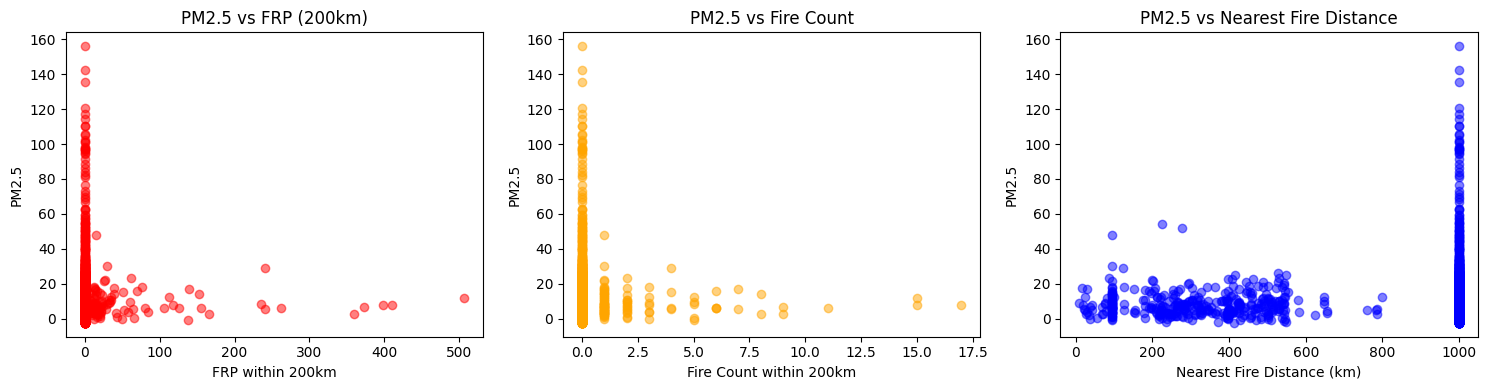

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 4))

# Plot 1: PM2.5 vs FRP 200km
plt.subplot(1, 3, 1)
plt.scatter(df_master["frp_200km"], df_master["PM25"], alpha=0.5, c="red")
plt.xlabel("FRP within 200km")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs FRP (200km)")

# Plot 2: PM2.5 vs Fires 200km
plt.subplot(1, 3, 2)
plt.scatter(df_master["fires_200km"], df_master["PM25"], alpha=0.5, c="orange")
plt.xlabel("Fire Count within 200km")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs Fire Count")

# Plot 3: PM2.5 vs Nearest Fire Distance
plt.subplot(1, 3, 3)
plt.scatter(df_master["nearest_fire_km"], df_master["PM25"], alpha=0.5, c="blue")
plt.xlabel("Nearest Fire Distance (km)")
plt.ylabel("PM2.5")
plt.title("PM2.5 vs Nearest Fire Distance")

plt.tight_layout()
plt.show()

Train samples: 5646 | Test samples: 1883

 Richmond XGBoost Performance 
MAE:  2.078
RMSE: 2.916
R²:   0.669


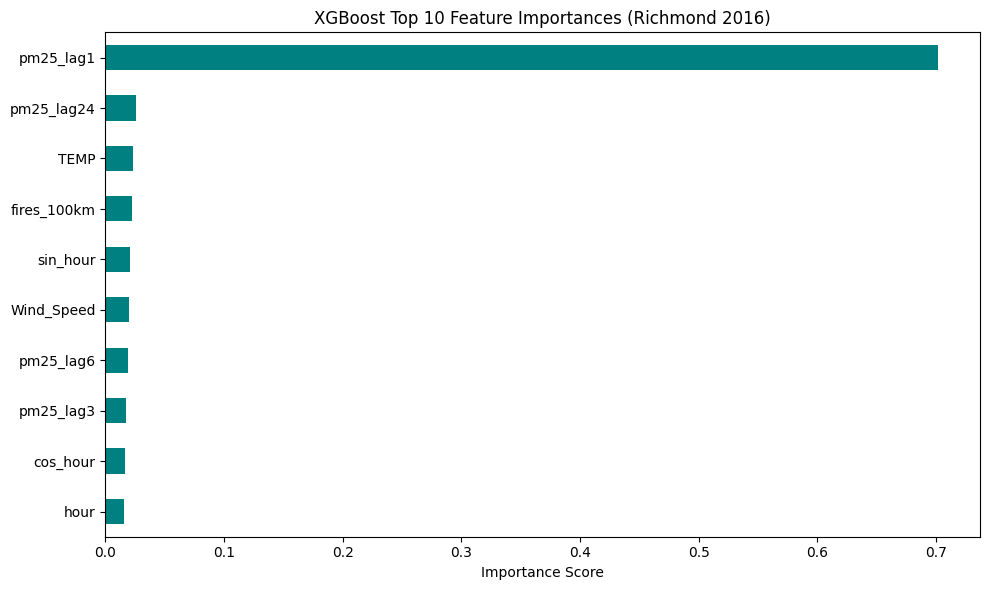

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Drop rows where target variable PM25 is NaN to ensure training works
df_model_data = df_master.dropna(subset=["PM25"]).reset_index(drop=True)

# Define features (X) and target (y)
# Exclude non-numeric metadata columns ('Date', 'Time', 'season')
ignore_cols = ["datetime", "station", "PM25", "Date", "Time", "season"]
feature_cols = [c for c in df_model_data.columns if c not in ignore_cols]

X = df_model_data[feature_cols]
y = df_model_data["PM25"]

# Time-based split: Train on first 75% of time, test on final 25%
split_idx = int(len(df_model_data) * 0.75)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# Train XGBoost Model
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)
model.fit(X_train, y_train)

# Predict & Evaluate
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n==============================")
print(" Richmond XGBoost Performance ")
print("==============================")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

# Plot Top 10 Feature Importances
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.tail(10).plot(kind="barh", color="teal")
plt.title("XGBoost Top 10 Feature Importances (Richmond 2016)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

Richmond 2016 Train Samples: 5646 | Test Samples: 1883
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000495 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2732
[LightGBM] [Info] Number of data points in the train set: 5646, number of used features: 25
[LightGBM] [Info] Start training from score 8.441870
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [War

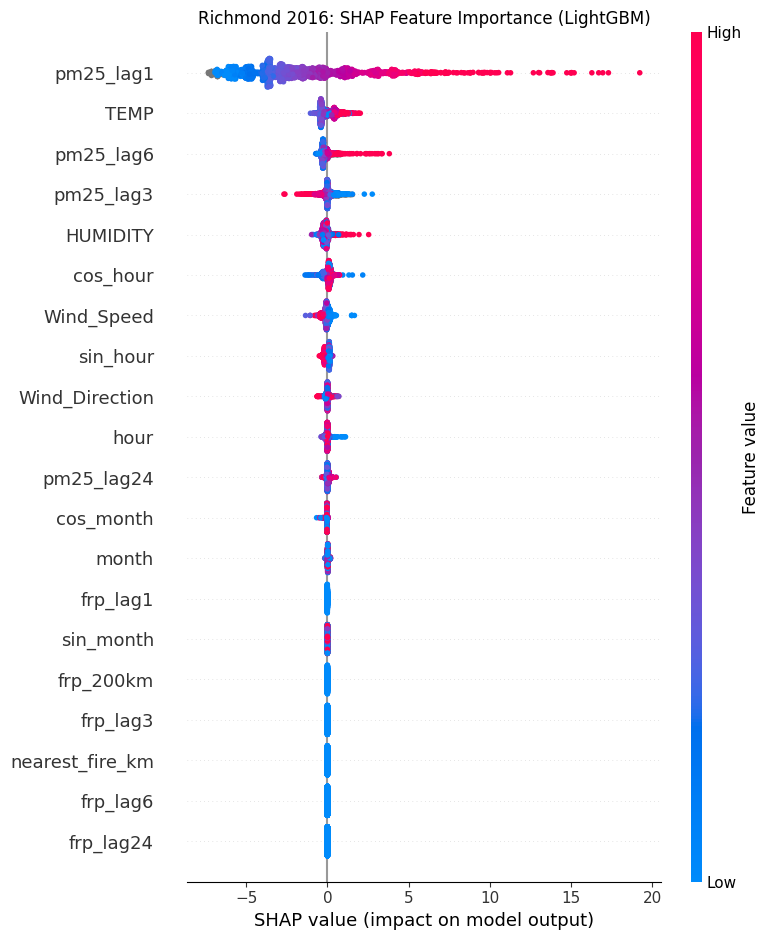

In [19]:
!pip install keras-tcn -q

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tcn import TCN

# ==========================================
# 1. LOAD DATASET & CHRONOLOGICAL SPLIT
# ==========================================
# Use the correct file created in Step 1
df_richmond = pd.read_csv("master_dataset_Richmond_2016.csv")
df_richmond["datetime"] = pd.to_datetime(df_richmond["datetime"])
df_richmond = df_richmond.sort_values("datetime").reset_index(drop=True)

# Define features (X) and target (y)
# Drop rows where target variable PM25 is NaN
df_richmond = df_richmond.dropna(subset=["PM25"]).reset_index(drop=True)
ignore_cols = ["datetime", "station", "PM25", "Date", "Time", "season"]
feature_cols = [c for c in df_richmond.columns if c not in ignore_cols]
target_col = "PM25"

# Chronological split: Train on first 75% of 2016, Test on remaining 25%
split_idx = int(len(df_richmond) * 0.75)

X_train = df_richmond.loc[: split_idx - 1, feature_cols]
y_train = df_richmond.loc[: split_idx - 1, target_col]
X_test = df_richmond.loc[split_idx:, feature_cols]
y_test = df_richmond.loc[split_idx:, target_col]

print(f"Richmond 2016 Train Samples: {len(X_train)} | Test Samples: {len(X_test)}")

# ==========================================
# 2. MODEL 1: LIGHTGBM REGRESSOR
# ==========================================
lgbm_model = LGBMRegressor(
    n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42
)
lgbm_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_model.predict(X_test)

mae_lgbm = mean_absolute_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mean_squared_error(y_test, y_pred_lgbm))
r2_lgbm = r2_score(y_test, y_pred_lgbm)

# ==========================================
# 3. SEQUENCE PREPARATION FOR DEEP LEARNING
# ==========================================
# Fill remain NaNs in features (if any, e.g., Rainfall) with 0 for Neural Networks
scaled_features_df = df_richmond[feature_cols].fillna(0)

# Standardize features and targets for Neural Networks
scaler_x = StandardScaler()
scaler_y = StandardScaler()

scaled_features = scaler_x.fit_transform(scaled_features_df)
scaled_target = scaler_y.fit_transform(df_richmond[[target_col]])


def create_sequences(features, target, window_size=24):
    """Creates 24-hour sliding window sequences for sequence models."""
    X_seq, y_seq = [], []
    for i in range(len(features) - window_size):
        X_seq.append(features[i : i + window_size])
        y_seq.append(target[i + window_size])
    return np.array(X_seq), np.array(y_seq)


# Generate sliding window arrays
X_seq_all, y_seq_all = create_sequences(scaled_features, scaled_target)

# Train/test split matching tabular index
X_train_seq = X_seq_all[: split_idx - 24]
y_train_seq = y_seq_all[: split_idx - 24]
X_test_seq = X_seq_all[split_idx - 24 :]
y_test_seq = y_seq_all[split_idx - 24 :]

# Actual test values (unscaled) for evaluation
y_test_dl_actual = scaler_y.inverse_transform(y_test_seq)

# ==========================================
# 4. MODEL 2: LSTM
# ==========================================
lstm_model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1),
])

lstm_model.compile(optimizer="adam", loss="mse")
lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=0,
)

preds_lstm_scaled = lstm_model.predict(X_test_seq)
preds_lstm = scaler_y.inverse_transform(preds_lstm_scaled)

mae_lstm = mean_absolute_error(y_test_dl_actual, preds_lstm)
rmse_lstm = np.sqrt(mean_squared_error(y_test_dl_actual, preds_lstm))
r2_lstm = r2_score(y_test_dl_actual, preds_lstm)

# ==========================================
# 5. MODEL 3: TCN (TEMPORAL CONVOLUTIONAL NET)
# ==========================================
tcn_model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),
    TCN(
        nb_filters=64,
        kernel_size=3,
        dilations=[1, 2, 4, 8],
        return_sequences=False,
    ),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1),
])

tcn_model.compile(optimizer="adam", loss="mse")
tcn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=0,
)

preds_tcn_scaled = tcn_model.predict(X_test_seq)
preds_tcn = scaler_y.inverse_transform(preds_tcn_scaled)

mae_tcn = mean_absolute_error(y_test_dl_actual, preds_tcn)
rmse_tcn = np.sqrt(mean_squared_error(y_test_dl_actual, preds_tcn))
r2_tcn = r2_score(y_test_dl_actual, preds_tcn)

# ==========================================
# 6. PRINT EVALUATION COMPARISON TABLE
# ==========================================
results_summary = pd.DataFrame([
    {"Model": "LightGBM", "MAE": mae_lgbm, "RMSE": rmse_lgbm, "R²": r2_lgbm},
    {"Model": "LSTM", "MAE": mae_lstm, "RMSE": rmse_lstm, "R²": r2_lstm},
    {"Model": "TCN", "MAE": mae_tcn, "RMSE": rmse_tcn, "R²": r2_tcn},
]).sort_values(by="RMSE")

print("\n=======================================================")
print("          RICHMOND 2016 MODEL BENCHMARK RESULTS         ")
print("=======================================================")
print(results_summary.to_string(index=False))

# ==========================================
# 7. SHAP EXPLAINABILITY (LIGHTGBM)
# ==========================================
print("\nGenerating SHAP Summary Plot...")
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show=False)
plt.title("Richmond 2016: SHAP Feature Importance (LightGBM)")
plt.tight_layout()
plt.show()